# Getting Started with an EMRI

The walk-through of `getting_started.ipynb`, with an extreme mass-ratio inspiral from FEW in place of the linear chirp. We build the waveform, create the `LISAresponse` class, and generate the six one arm response links.

## 0. Imports & Parameters

In [1]:
#here are all the necessary imports 

import time

import jax
import numpy as np
import matplotlib.pyplot as plt

from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits

from WDM_LISAresponse.code.waveforms import waveforms

from WDM_LISAresponse.code.utils import utils

import WDM
from WDM.code.plotting.plotting import time_frequency_plot

from WDM_LISAresponse import LISAresponse

We also set-up the parameters for the example.

In [2]:
N = 2 ** 22 #number of samples
dt = 10 #seconds

# Sky position of the source in the solar-system barycentric frame of the
# orbit file: theta is the polar angle from +z, phi the azimuth from +x.
# Together they give the unit vector n from the barycentre towards the
# source (the wave travels along -n); the latitude is pi/2 - theta.
theta = np.pi/3
phi = np.pi/6

Nf = 128
max_lag = 25

## 1. Orbit file 

We load the `esa-trailing-orbits.h5` file, which encodes the breathing LISA satellite orbits.

In [3]:
data = read_orbit_file('esa-trailing-orbits.h5')

times_orbits = data.t0 + data.dt * np.arange(data.size)

orbits = InterpolatedOrbits(times_orbits, data.positions, data.velocities)

lead_in = 1280.0                  # must exceed one light-travel time (~8.4 s)
t0 = times_orbits[0] + lead_in    # absolute time of the first *padded* sample

## 2. Waveform

The EMRI comes from FEW through `waveforms.emri_generator()`, which memory-maps FEW's amplitude table instead of reading it into memory. Building the generator takes about ten seconds, so it has a cell of its own.

In [4]:
# FEW's Kerr eccentric equatorial model; re-running this cell reuses it.
if "td_gen" not in globals():
    td_gen = waveforms.emri_generator()

In [5]:
tukey_alpha = 0.01
emri_params = dict(
    m1=1.0e6, m2=10.0, a=0.9, p0=12.0, e0=0.3, x0=1.0, dist=1.0,
    theta=theta, phi=phi,            # the same sky position the response uses
    qK=np.pi/3, phiK=np.pi/3,
    Phi_phi0=np.pi/3, Phi_theta0=0.0, Phi_r0=np.pi/3,
    eps=1.0e-2,
)
times, h_plus, h_cross = waveforms.generate_windowed_waveform(
    "emri", t0=t0, dt=dt, N=N,
    model_kwargs=dict(td_gen=td_gen, **emri_params),
    window_function="tukey", window_kwargs=dict(alpha=tukey_alpha))

#after generating the signal we pad it according to specifications

pad_info = utils.wdm_padding_info(n_samples = N,
                                  Nf = Nf,
                                  max_lag_L= max_lag)

for key in ("input_length", "pad_left", "pad_right", "target_length"):
    print(f"{key:>13} : {pad_info[key]:>8} samples")
for key in ("rows_left", "rows_right", "guard_rows", "Nt"):
    print(f"{key:>13} : {pad_info[key]:>8} rows")
print(f"{'Nf':>13} : {pad_info['Nf']:>8} bands")

#we apply the padding to the waveform and data range 

times_pad, h_plus_pad, h_cross_pad = utils.apply_zero_padding(times, h_plus, h_cross, pad_info['pad_left'], pad_info['pad_right'])

 input_length :  4194304 samples
     pad_left :     1792 samples
    pad_right :     1792 samples
target_length :  4197888 samples
    rows_left :       14 rows
   rows_right :       14 rows
   guard_rows :       13 rows
           Nt :    32796 rows
           Nf :      128 bands


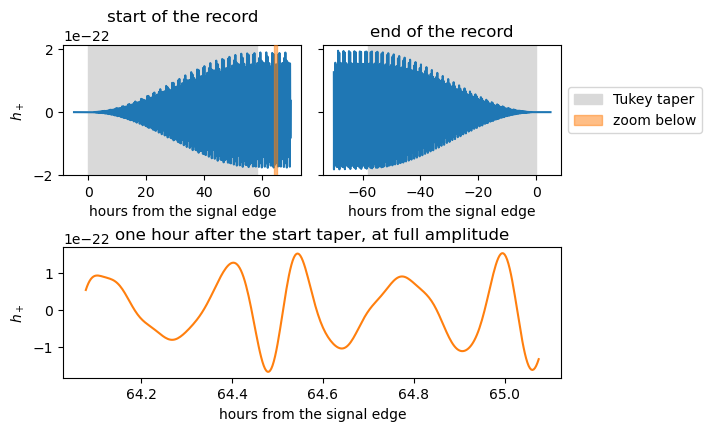

In [6]:
# The padded record at both ends: the zero padding, then the Tukey taper
# (shaded) bringing the signal smoothly up to full amplitude and back down.
# The oscillation is far too dense to resolve at this scale, so the bottom
# panel zooms into one hour just after the start taper (marked in orange).
taper = int(tukey_alpha / 2 * N)                 # samples in each taper
start = pad_info["pad_left"]                     # first signal sample
stop = len(times_pad) - pad_info["pad_right"]    # first padding sample after it
hour = int(3600 / dt)
zoom = slice(start + taper + taper // 10, start + taper + taper // 10 + hour)


def hours_from(sl, edge):
    return (times_pad[sl] - times_pad[edge]) / 3600


fig, axes = plt.subplot_mosaic([["start", "end"], ["zoom", "zoom"]],
                               figsize=(7, 4.2), layout="constrained")
ends = {"start": (slice(0, start + taper + taper // 5), start, (0, 1), "start of the record"),
        "end": (slice(stop - taper - taper // 5, None), stop, (-1, 0), "end of the record")}
for key, (sl, edge, span, title) in ends.items():
    axes[key].plot(hours_from(sl, edge), h_plus_pad[sl])
    axes[key].axvspan(*(s * taper * dt / 3600 for s in span), color="0.85", zorder=0,
                      label="Tukey taper")
    axes[key].set(xlabel="hours from the signal edge", title=title)
axes["end"].sharey(axes["start"])
axes["end"].tick_params(labelleft=False)
axes["start"].set_ylabel("$h_+$")

in_hours = hours_from(zoom, start)
axes["start"].axvspan(in_hours[0], in_hours[-1], color="C1", alpha=0.5, zorder=3, label="zoom below")
axes["end"].legend(*axes["start"].get_legend_handles_labels(), loc="center left", bbox_to_anchor=(1, 0.5))

axes["zoom"].plot(in_hours, h_plus_pad[zoom], color="C1")
axes["zoom"].set(xlabel="hours from the signal edge", ylabel="$h_+$",
                 title="one hour after the start taper, at full amplitude")
plt.show()

## 3. Response in Time-frequency domain

We first generate the WDM class, which is responsible for the transformation.

In [7]:
wdm = WDM.WDM.WDM_transform(dt=dt, Nf=Nf, N=len(times_pad))

print(wdm)

WDM_transform(Nf=128, N=4197888, q=16, d=4, A_frac=0.25)
self.Nt = 32796 time cells
self.Nf = 128 frequency cells
self.dT = 1280.0 time resolution
self.dF = 0.000390625 frequency resolution
self.dt = 10.0 time series cadence
self.df = 2.3821502622271008e-08 time series fft frequency resolution
self.K = 4096 window length


Then, we visualise the two polarisations in the time-frequency domain.

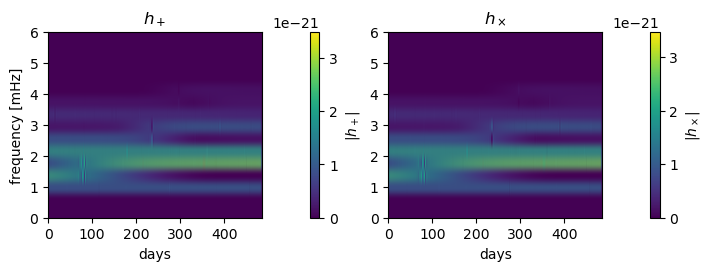

In [8]:
wdm_h_plus = wdm(h_plus_pad)
wdm_h_cross = wdm(h_cross_pad)

days, mhz = [0, 100, 200, 300, 400], [0, 1, 2, 3, 4, 5, 6]

fig, axes = plt.subplots(1, 2, figsize=(7, 2.6), layout="constrained")
for ax, w, name in zip(axes, (wdm_h_plus, wdm_h_cross), ("h_+", r"h_\times")):
    time_frequency_plot(wdm, w, figax=(fig, ax), part="abs", cmap="viridis", label=f"$|{name}|$")
    ax.set_xticks([d * 86400 for d in days], labels=days)
    ax.set_yticks([m * 1e-3 for m in mhz], labels=mhz)
    ax.set(xlabel="days", ylabel="", ylim=(0, 6e-3), title=f"${name}$")
axes[0].set_ylabel("frequency [mHz]")
plt.show()

We then create the LISAresponse class, which is responsible for computing the response.

In [9]:
response = LISAresponse(wdm_class=wdm, orbits_class=orbits, t0=t0, max_lag_L=max_lag, num_interp_points=16)

print(response)

LISAresponse(max_lag_L=25, num_interp_points=16)
record       [2073212410.8175, 2115191290.8175] s TCB, 485.87 d
orbits       InterpolatedOrbits, span [2073211130.8175, 2351489855.5637] s; t0 is 1280.0 s after its start
links        6: (Link(2->1), Link(3->2), Link(1->3), Link(3->1), Link(2->3), Link(1->2))
light time   8.154404 to 8.414449 s
wdm_class:
    WDM_transform(Nf=128, N=4197888, q=16, d=4, A_frac=0.25)
    self.Nt = 32796 time cells
    self.Nf = 128 frequency cells
    self.dT = 1280.0 time resolution
    self.dF = 0.000390625 frequency resolution
    self.dt = 10.0 time series cadence
    self.df = 2.3821502622271008e-08 time series fft frequency resolution
    self.K = 4096 window length


We compute the response for our supplied waveform. The default calculation takes input in WDM domain and outputs six links in the WDM domain. Look at function `one_arm_response` in `response.py` if you want to vary this. 

By default, we calculate all six links, if you want to compute a subset, use the `utils.py` function `Link`.

In [10]:
start = time.perf_counter()
wdm_one_arm_responses = jax.block_until_ready(
    response(theta=theta, phi=phi, h_plus=wdm_h_plus, h_cross=wdm_h_cross))
first_call = time.perf_counter() - start

print(wdm_one_arm_responses.shape)
print(f"{first_call:.1f} s, including JAX compilation on this first call")

(6, 32796, 128)
4.1 s, including JAX compilation on this first call


By default, we calculate all six links in order: $(s,r) = [(2, 1), (3, 2),(1, 3), (3, 1), (2, 3), (1, 2)]$.  
If you want to compute a subset, use the `utils.py` function `Link`.

In [11]:
start = time.perf_counter()
wdm_one_arm_response_12 = jax.block_until_ready(response.one_arm_response(
    theta=theta, phi=phi, h_plus=wdm_h_plus, h_cross=wdm_h_cross, link=utils.Link(1, 2)))

print(wdm_one_arm_response_12.shape)
print(f"{time.perf_counter() - start:.1f} s, including JAX compilation on this first call")

(32796, 128)
0.7 s, including JAX compilation on this first call


## 4. Comparison in Time Domain

We compute the time domain response, note that this method is slower.

In [12]:
start = time.perf_counter()
td_one_arm_responses = jax.block_until_ready(response.one_arm_response_time_domain(
    theta=theta, phi=phi, h_plus=h_plus_pad, h_cross=h_cross_pad))

print(td_one_arm_responses.shape)
print(f"{time.perf_counter() - start:.1f} s")

(6, 4197888)
19.7 s


Now we compare the two approaches together, by computing L2 error and mismatch, and by plotting.

In [13]:
#we calculate the cut information for the grids to compare signals 

cut_info = utils.wdm_cut_info(pad_info=pad_info)

for key, value in cut_info.items():
    print(key,":", value)

td_one_arm_responses_in_wdm = wdm(td_one_arm_responses)

wdm_one_arm_responses_cut = utils.apply_wdm_cut(wdm_one_arm_responses, cut_info=cut_info)
print("")
print("The dimensions after applying a cut are:", wdm_one_arm_responses_cut.shape)
print("")
td_one_arm_responses_in_wdm_cut= utils.apply_wdm_cut(td_one_arm_responses_in_wdm, cut_info=cut_info)

for i in np.arange(6):
    res = utils.wdm_mismatch(wdm_one_arm_responses_cut[i,:,:], td_one_arm_responses_in_wdm_cut[i,:,:])
    print(response.link_convention[i])
    print(" Mismatch:", res['mismatch'])
    print(" L2 error:", res['rel_L2'])



wdm_Nt : 32796
Nf : 128
rows_cut_left : 14
rows_cut_right : 14
time_slice : slice(14, 32782, None)
freq_slice : slice(1, None, None)

The dimensions after applying a cut are: (6, 32768, 127)

Link(2->1)
 Mismatch: 3.610960701244323e-07
 L2 error: 0.0009295965999060712
Link(3->2)
 Mismatch: 5.085477842188859e-07
 L2 error: 0.0010700698595039182
Link(1->3)
 Mismatch: 3.7753449279602786e-07
 L2 error: 0.0009339361235675467
Link(3->1)
 Mismatch: 3.7799590236807063e-07
 L2 error: 0.000935232026685019
Link(2->3)
 Mismatch: 5.159957616729682e-07
 L2 error: 0.0010760537150749168
Link(1->2)
 Mismatch: 3.590362633998778e-07
 L2 error: 0.0009289122780236767


From the results above, the EMRI's links agree with the time-domain path to an L2 error of $\sim 10^{-3}$ and a mismatch of $4$-$5\times10^{-7}$, all six under the SNR-100 threshold of $5\times10^{-5}$ (for what sets this, see `accuracy_analysis.ipynb`).

We also plot link $2\rightarrow 1$: the change in its light travel time over the full record, where the yearly modulation shows, and a few cycles at the centre, where the two methods can be compared by eye.

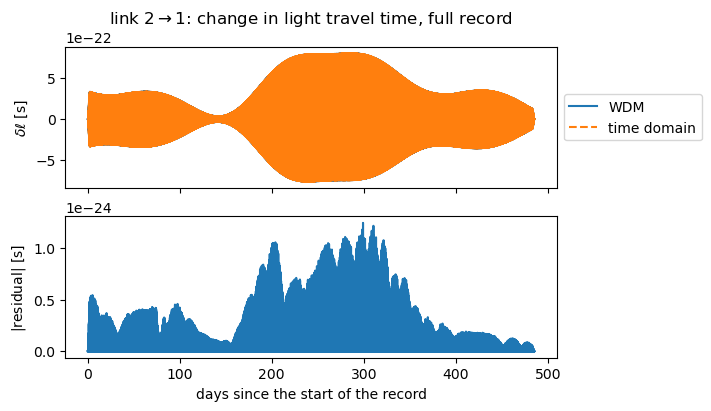

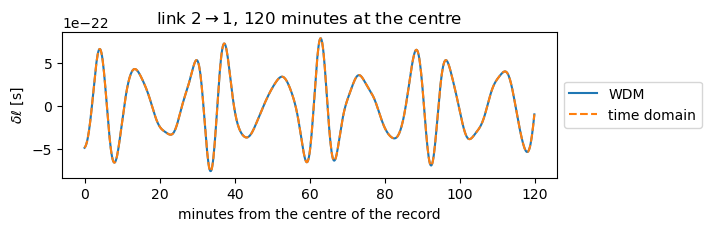

In [14]:
# Row 0 is link 2 -> 1 (sender 2, receiver 1).
wdm_one_arm_response_21_in_td = np.asarray(wdm.idwt(wdm_one_arm_responses[0]))
td_one_arm_response_21 = np.asarray(td_one_arm_responses[0])

# The full record, on the rows the mismatch above is computed on. The mHz
# oscillation is far too fast to resolve here, but the width of the band follows
# its amplitude, which is modulated over the year as the constellation turns.
interior = slice(cut_info["rows_cut_left"] * Nf,
                 (cut_info["wdm_Nt"] - cut_info["rows_cut_right"]) * Nf)
days = (times_pad[interior] - t0) / 86400

fig, axes = plt.subplots(2, 1, figsize=(7, 4), sharex=True, layout="constrained")
axes[0].plot(days, wdm_one_arm_response_21_in_td[interior], label="WDM")
axes[0].plot(days, td_one_arm_response_21[interior], ls="--", label="time domain")
axes[0].set(ylabel=r"$\delta\ell$ [s]",
            title=r"link $2 \rightarrow 1$: change in light travel time, full record")
axes[0].legend(loc="center left", bbox_to_anchor=(1, 0.5))

axes[1].plot(days, np.abs(td_one_arm_response_21 - wdm_one_arm_response_21_in_td)[interior])
axes[1].set(xlabel="days since the start of the record", ylabel=r"$|$residual$|$ [s]")
plt.show()

# A few cycles at the centre, where the two curves can be told apart.
centre = len(times_pad) // 2
zoom = slice(centre, centre + int(120 * 60 / dt))
minutes = (times_pad[zoom] - times_pad[centre]) / 60

fig, ax = plt.subplots(figsize=(7, 2.2), layout="constrained")
ax.plot(minutes, wdm_one_arm_response_21_in_td[zoom], label="WDM")
ax.plot(minutes, td_one_arm_response_21[zoom], ls="--", label="time domain")
ax.set(xlabel="minutes from the centre of the record", ylabel=r"$\delta\ell$ [s]",
       title=r"link $2 \rightarrow 1$, 120 minutes at the centre")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

## Comparison in WDM Domain

Finally, link $1\rightarrow 2$, the one computed on its own above, compared directly on the wavelet grid: the two methods side by side, then their difference.

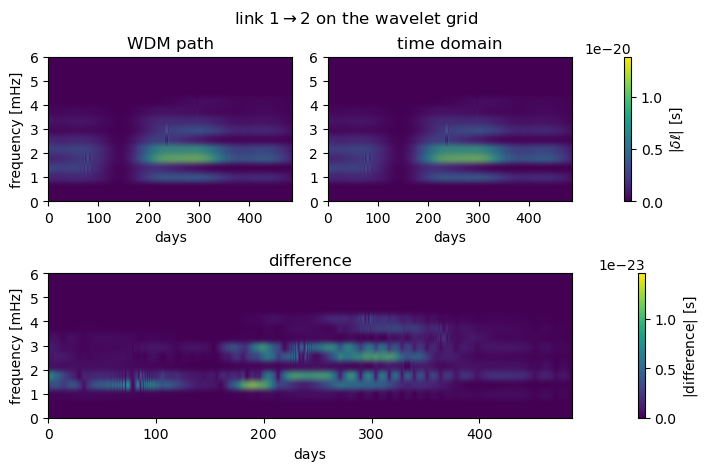

In [15]:
k = list(response.link_convention).index(utils.Link(1, 2))
grids_12 = {"WDM path": np.asarray(wdm_one_arm_response_12),
            "time domain": np.asarray(td_one_arm_responses_in_wdm[k])}
difference = grids_12["WDM path"] - grids_12["time domain"]

# Colour limits from the region the mismatch uses, so the padding and the m = 0
# band do not set them.
signal_max = max(np.abs(utils.apply_wdm_cut(g, cut_info)).max() for g in grids_12.values())
difference_max = np.abs(utils.apply_wdm_cut(difference, cut_info)).max()
day_ticks, mhz_ticks = [0, 100, 200, 300, 400], [0, 1, 2, 3, 4, 5, 6]

fig, axes = plt.subplot_mosaic([["WDM path", "time domain"],
                                ["difference", "difference"]],
                               figsize=(7, 4.6), layout="constrained")
for name, grid in grids_12.items():
    time_frequency_plot(wdm, grid, figax=(fig, axes[name]), part="abs", cmap="viridis",
                        vmin=0, vmax=signal_max, label=r"$|\delta\ell|$ [s]")
# The two share a colour scale, so one colour bar serves both.
axes["WDM path"].images[0].colorbar.remove()
time_frequency_plot(wdm, difference, figax=(fig, axes["difference"]), part="abs", cmap="viridis",
                    vmin=0, vmax=difference_max, label=r"$|$difference$|$ [s]")
for name, ax in axes.items():
    ax.set_xticks([d * 86400 for d in day_ticks], labels=day_ticks)
    ax.set_yticks([m * 1e-3 for m in mhz_ticks], labels=mhz_ticks)
    ax.set(title=name, xlabel="days", ylim=(0, 6e-3),
           ylabel="" if name == "time domain" else "frequency [mHz]")
fig.suptitle(r"link $1 \rightarrow 2$ on the wavelet grid")
plt.show()

### JIT Compilation 

The package is written fully in JAX: the first evaluation compiles, and every later one with the same settings and array sizes reuses the compiled code, even from a new `LISAresponse`. Below, we clear JAX's cache first so the compilation cost shows again.

In [16]:
# JAX caches compiled code by function and array shapes, not by object, so a
# new LISAresponse with the same settings would reuse what the calls above
# compiled. Clearing the cache makes the first call below compile again.
jax.clear_caches()
fresh_response = LISAresponse(wdm_class=wdm, orbits_class=orbits, t0=t0,
                              max_lag_L=max_lag, num_interp_points=16)

for call in (1, 2):
    start = time.perf_counter()
    jax.block_until_ready(fresh_response(theta=theta, phi=phi, h_plus=wdm_h_plus, h_cross=wdm_h_cross))
    note = "  (includes compilation)" if call == 1 else ""
    print(f"call {call}: {time.perf_counter() - start:.2f} s{note}")

call 1: 4.28 s  (includes compilation)
call 2: 0.68 s
